Downloaded!
Extracted!
Dataset is ready
Total messages: 5572
Spam: 747
Ham: 4825

First few rows:
  label  \
0   ham   
1   ham   
2  spam   
3   ham   
4   ham   

                                                                                                                                                       message  
0                                              Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...  
1                                                                                                                                Ok lar... Joking wif u oni...  
2  Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's  
3                                                                                                            U dun say so early hor... U c already then say...  
4                             

,text,category
0,"xxbos xxmaj sad story of a xxmaj man - xxmaj last week was my b'day . xxmaj my xxmaj wife did'nt wish me . xxmaj my xxmaj parents forgot n so did my xxmaj kids . i went to work . xxmaj even my xxmaj colleagues did not wish . xxmaj as i entered my cabin my xxup pa said , '' xxmaj happy xxmaj b'day xxmaj boss ! ! '' . i felt special . xxmaj she askd me 4 lunch . xxmaj after lunch she invited me to her apartment . xxmaj we went there . xxmaj she said , '' do u mind if i go into the bedroom for a minute ? '' '' ok '' , i sed in a sexy mood . xxmaj she came out 5 minuts latr wid a cake … n xxmaj my xxmaj wife , xxmaj my xxmaj parents ,",ham
1,xxbos xxmaj for me the love should start with xxunk should feel that i need her every time around xxunk should be the first thing which comes in my xxunk would start the day and end it with xxunk should be there every time i xxunk will be then when my every xxunk has her xxunk life should happen around xxunk life will be xxunk to xxunk would cry for xxunk give all my happiness and take all her xxunk will be ready to fight with anyone for xxunk will be in love when i will be doing the xxunk things for xxunk will be when i do n't have to xxunk anyone that my girl is the most beautiful lady on the whole xxunk will always be xxunk xxunk for xxunk will be when i start up making xxunk xxunk and end up xxunk xxunk will be the most,ham
2,"xxbos no , i * did n't * mean to post it . i xxunk it , and like so many other times i 've xxunk stuff to you , i let it sit there . it xxup was what i was feeling at the time . i was angry . xxmaj before i left , i hit send , then stop . xxmaj it was n't there . i checked on my phone when i got to my car . xxmaj it was n't there . xxmaj you said you did n't sleep , you were bored . xxmaj so why would n't xxup that be the time to clean , xxunk xxunk , etc . ? xxmaj at least make the bed ?",ham



Building model...
Model ready

Finding learning rate...


<div></div>


Training model...
This might take 10-15 minutes



epoch,train_loss,valid_loss,accuracy,precision_score,recall_score,f1_score,time
0,0.425232,0.102585,0.959596,0.824818,0.904000,0.862595,00:07


... (2 outputs left out)

Loss: 0.0406
Accuracy: 0.9921
Precision: 0.9917
Recall: 0.9520
F1: 0.9714

Trying some test messages:



Message: "WINNER!! You have won a $1000 prize! Call now!"
Model says: spam
Confidence: 0.9776



Message: "Hey, are we still meeting for lunch tomorrow?"
Model says: ham
Confidence: 0.9732



Message: "FREE entry to a cash prize! Text WIN to 12345"
Model says: spam
Confidence: 0.9970


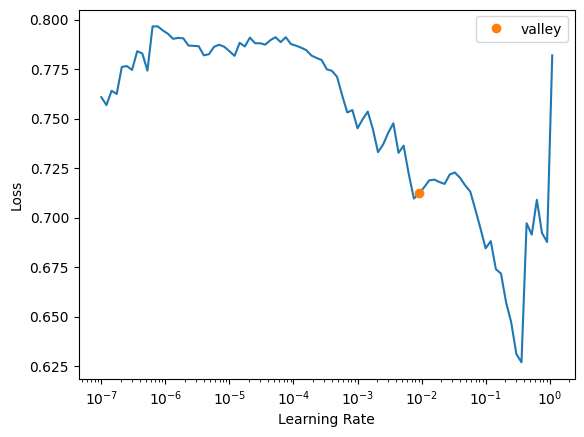

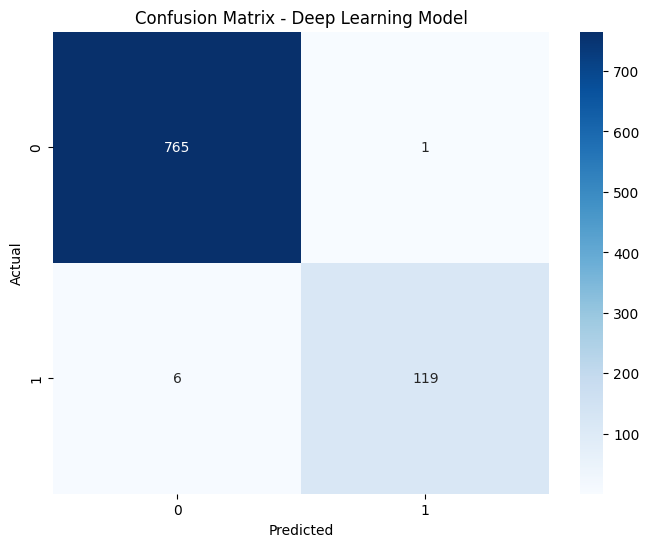


Detailed results:
              precision    recall  f1-score   support

         ham       0.99      1.00      1.00       766
        spam       0.99      0.95      0.97       125

    accuracy                           0.99       891
   macro avg       0.99      0.98      0.98       891
weighted avg       0.99      0.99      0.99       891

Saved model


In [1]:
# SMS SPAM DETECTION - DEEP LEARNING MODEL
# Using AWD_LSTM with transfer learning


#  Install what I need
# Getting fastai library installed
!pip install -Uqq fastai

#  Import stuff
# Bringing in all the libraries
from fastai.text.all import *
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import urllib.request
import zipfile
import os

#  Download the dataset
# Grabbing the SMS spam data from UCI
print('Downloading dataset...')

url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip'
zip_path = 'smsspamcollection.zip'

# Download and extract
urllib.request.urlretrieve(url, zip_path)
print('Downloaded!')

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall('.')
print('Extracted!')

# Make sure file is there
if os.path.exists('SMSSpamCollection'):
    print('Dataset is ready')

# Load the data
# Reading the file - it uses tabs to separate columns
df = pd.read_csv('SMSSpamCollection', sep='\t', names=['label', 'message'])

print(f'Total messages: {len(df)}')
print(f'Spam: {len(df[df.label == "spam"])}')
print(f'Ham: {len(df[df.label == "ham"])}')
print('\nFirst few rows:')
print(df.head())

#  Check the balance
# Seeing how much spam vs ham we have
print('\nBreakdown:')
print(df['label'].value_counts())
print(f'\nSpam is {(df.label == "spam").sum() / len(df) * 100:.2f}% of data')

#  Look at examples
# Checking what spam and ham messages look like
print('Some spam examples:')
for msg in df[df.label == 'spam'].head(3)['message'].values:
    print(f'  - {msg}')
print('\nSome regular messages:')
for msg in df[df.label == 'ham'].head(3)['message'].values:
    print(f'  - {msg}')

#  Split into train and test
# Saving 20% for testing later
from sklearn.model_selection import train_test_split

train_df, valid_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df['label'])

print(f'\nTraining set: {len(train_df)} messages')
print(f'Validation set: {len(valid_df)} messages')

# Set up fastai data
# Getting data ready for the model
dls = TextDataLoaders.from_df(
    train_df,
    valid_df=valid_df,
    text_col='message',
    label_col='label',
    bs=32
)

# Look at one batch
print('\nSample batch:')
dls.show_batch(max_n=3)

# Build the model
# Creating AWD_LSTM classifier with transfer learning
print('\nBuilding model...')
learn = text_classifier_learner(
    dls, 
    AWD_LSTM,
    drop_mult=0.5,
    metrics=[accuracy, Precision(), Recall(), F1Score()]
)
print('Model ready')

# Find learning rate
# Checking what learning rate works best
print('\nFinding learning rate...')
learn.lr_find()

#  Train it
# This takes a while - training for 4 epochs
print('\nTraining model...')
print('This might take 10-15 minutes\n')
learn.fine_tune(4, base_lr=1e-2)

#  Check results
# Seeing how well it did
print('\nFinal results:')
results = learn.validate()
print(f'Loss: {results[0]:.4f}')
print(f'Accuracy: {results[1]:.4f}')
print(f'Precision: {results[2]:.4f}')
print(f'Recall: {results[3]:.4f}')
print(f'F1: {results[4]:.4f}')

# Try some examples
# Testing with real messages
print('\nTrying some test messages:\n')

# Spam test
test1 = "WINNER!! You have won a $1000 prize! Call now!"
pred1 = learn.predict(test1)
print(f'Message: "{test1}"')
print(f'Model says: {pred1[0]}')
print(f'Confidence: {pred1[2].max():.4f}\n')

# Normal message test
test2 = "Hey, are we still meeting for lunch tomorrow?"
pred2 = learn.predict(test2)
print(f'Message: "{test2}"')
print(f'Model says: {pred2[0]}')
print(f'Confidence: {pred2[2].max():.4f}\n')

# Another spam test
test3 = "FREE entry to a cash prize! Text WIN to 12345"
pred3 = learn.predict(test3)
print(f'Message: "{test3}"')
print(f'Model says: {pred3[0]}')
print(f'Confidence: {pred3[2].max():.4f}')

#  Confusion matrix
# Making a confusion matrix to see where it got confused
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt

val_preds, val_targets = learn.get_preds()
val_preds_labels = val_preds.argmax(dim=1)

cm = confusion_matrix(val_targets, val_preds_labels)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - Deep Learning Model')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

print('\nDetailed results:')
print(classification_report(val_targets, val_preds_labels, target_names=['ham', 'spam']))


# Saving model to use later
learn.export('spam_detector_dl.pkl')
# print('Saved model')